<a href="https://colab.research.google.com/github/mrcastilla8/Labs-Mineria/blob/master/Semana%2013/Breast_Cancer_Clasificacion_Laboratorio_Grupal_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de tumores mamarios con aprendizaje supervisado

**Laboratorio académico | Ejercicio 3 | Breast Cancer Wisconsin (Diagnostic)**

Este trabajo explora el conjunto Breast Cancer Wisconsin (Diagnostic), prepara sus predictores y compara cinco clasificadores binarios mediante una partición estratificada de entrenamiento y prueba. La clase positiva es **M = maligno (1)**; **B = benigno (0)**. Se documentan la exploración descriptiva, el preprocesamiento, las métricas y las limitaciones de la evaluación.

La comparación es un ejercicio metodológico y no constituye una herramienta diagnóstica ni evidencia de utilidad clínica.

## Descripción del conjunto de datos

Se utiliza el conjunto **Breast Cancer Wisconsin (Diagnostic)**. Las características proceden del análisis de imágenes digitalizadas de aspirados con aguja fina (FNA) y describen propiedades geométricas y de textura de los núcleos celulares.

- **Problema:** clasificación binaria supervisada; `M` = maligno y `B` = benigno.
- **Registros esperados:** 569, de los cuales 212 son malignos y 357 benignos.
- **Predictores:** 30 variables numéricas originales.
- **Fuente del experimento:** archivo `Semana 13/dataset/data.csv` del repositorio, cargado localmente o recuperado desde un commit fijo del repositorio.
- **Preparación:** se descartan `id` y posibles columnas vacías de exportación; `diagnosis` se reserva como etiqueta y se verifican las ausencias antes de la partición.
- **Referencia de origen:** [UCI Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

La codificación es **1 = M (maligno, clase positiva)** y **0 = B (benigno)**, utilizada en predicciones, métricas, curvas ROC y matrices de confusión.

Este laboratorio es académico; sus predicciones **no constituyen diagnósticos clínicos**.

## Entorno y reproducibilidad

El análisis utiliza Python 3 y no requiere GPU. La sección 1.1 localiza el archivo original `Semana 13/dataset/data.csv` o lo recupera desde el commit fijo del repositorio. La celda informa la fuente efectiva y la huella SHA-256 para identificar el archivo de entrada. La carga desde GitHub requiere conexión a Internet.

## 0. Configuración experimental

### 0.1. Entorno de cómputo y configuración

El entorno reúne las bibliotecas para manipulación tabular, cálculo numérico, visualización y clasificación. La semilla fijada en el código favorece que la partición y los estimadores aleatorios puedan reproducirse; no garantiza resultados idénticos entre versiones distintas de las bibliotecas.

In [1]:
import sys

if sys.version_info.major != 3:
    raise RuntimeError("Este notebook requiere Python 3.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (8, 5), "axes.titlesize": 13,
                     "axes.labelsize": 11, "figure.dpi": 100})
print(
    f"Python {sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro} | "
    f"NumPy {np.__version__} | pandas {pd.__version__} | "
    f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | "
    f"seaborn {sns.__version__} | RANDOM_STATE={RANDOM_STATE}"
)

Python 3.13.18 | NumPy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0 | seaborn 0.13.2 | RANDOM_STATE=42


### 0.2. Estructuras de datos y modelos

La carga y limpieza se representan en `df_raw` y `df_clean`; `X` y `y` contienen predictores y etiqueta, y las variables `train/test` representan la partición. Los diccionarios identifican cada clasificador y el tipo de matriz utilizado.

In [2]:
modelos_entrenados = {}
tipo_entrada = {}
NOMBRES_MODELOS = (
    "Regresión logística", "KNN", "SVM", "Árbol de decisión", "Random Forest"
)
print("Registro de modelos preparado. Convención objetivo: 1=M (maligno), 0=B (benigno).")

Registro de modelos preparado. Convención objetivo: 1=M (maligno), 0=B (benigno).


## 1. Conjunto de datos

### 1.1. Carga del conjunto de datos

El CSV original del ejercicio constituye la fuente de los datos y la URL de descarga identifica el commit que contiene el archivo. La huella SHA-256 y las dimensiones registran la identidad e integridad del archivo utilizado.

In [3]:
# Carga reproducible del CSV original del experimento.
from pathlib import Path
from urllib.request import urlopen
from IPython.display import display
import hashlib
import pandas as pd

rutas_csv = [
    Path("/content/dataset/data.csv"),
    Path("dataset/data.csv"),
    Path("Semana 13/dataset/data.csv"),
]
ruta_csv = next((ruta for ruta in rutas_csv if ruta.is_file()), None)

if ruta_csv is None:
    ruta_csv = Path("/content/dataset/data.csv")
    ruta_csv.parent.mkdir(parents=True, exist_ok=True)
    url_csv = "https://raw.githubusercontent.com/mrcastilla8/Labs-Mineria/53d12095b79a66e903b9608c203c1b929012260b/Semana%2013/dataset/data.csv"
    try:
        with urlopen(url_csv, timeout=30) as respuesta:
            contenido_csv = respuesta.read()
    except Exception as exc:
        raise RuntimeError(
            "No se pudo descargar el CSV original desde GitHub. "
            "Comprueba la conexión de Colab y el acceso al repositorio; "
            "o carga manualmente el archivo en /content/dataset/data.csv. "
            "No se sustituye silenciosamente por el dataset de sklearn."
        ) from exc
    if not contenido_csv:
        raise RuntimeError("La descarga del CSV devolvió un archivo vacío.")
    ruta_csv.write_bytes(contenido_csv)
    print("CSV original descargado del commit fijo: 53d12095b79a66e903b9608c203c1b929012260b")
else:
    print("CSV original encontrado localmente:", ruta_csv)

# Verificar el archivo completo, incluso si ya estaba cargado en /content.
# Git usa SHA-1 de: b"blob " + longitud + b"\0" + contenido.
bytes_csv = ruta_csv.read_bytes()
prefijo_git = b"blob " + str(len(bytes_csv)).encode("ascii") + bytes([0])
huella_git = hashlib.sha1(prefijo_git + bytes_csv).hexdigest()
if huella_git != "407af7079c9711633e3c9dcd773782023eff30f5":
    raise ValueError(
        "El archivo local no coincide con Semana 13/dataset/data.csv del commit fijado. "
        "Sustituye /content/dataset/data.csv por el CSV original del repositorio. "
        f"Git blob observado: {huella_git}"
    )

df_raw = pd.read_csv(ruta_csv)
if "diagnosis" not in df_raw.columns:
    raise ValueError("El CSV debe contener la columna diagnosis (M/B).")
if len(df_raw) != 569:
    raise ValueError(f"Se esperaban 569 registros del dataset original; se obtuvieron {len(df_raw)}.")

fuente_datos = f"CSV original: {ruta_csv}"
huella_csv = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
print(f"Fuente utilizada: {fuente_datos}")
print(f"SHA-256 del CSV: {huella_csv}")
print(f"Dimensiones originales: {df_raw.shape[0]} filas × {df_raw.shape[1]} columnas")
display(df_raw.head())


CSV original encontrado localmente: /content/dataset/data.csv
Fuente utilizada: CSV original: /content/dataset/data.csv
SHA-256 del CSV: 27f219231dbb30eecbfc1361407ed641ea01be43316e2c707a1baf82c9795e23
Dimensiones originales: 569 filas × 33 columnas


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### 1.2. Validación inicial y limpieza

La inspección distingue columnas identificadoras o de exportación de las mediciones que describen las muestras. Se conserva la etiqueta `diagnosis`, se trabaja sobre una copia y se informa el estado de duplicados y valores ausentes. No se eliminan observaciones por duplicación sin una justificación basada en el contenido.

In [4]:
# 1.2 Validación inicial y limpieza sin alterar df_raw
import pandas as pd
from IPython.display import display

print("Dimensiones antes de limpiar:", df_raw.shape)
print("Tipos de datos originales:")
display(df_raw.dtypes.rename("tipo").to_frame())
print("Filas duplicadas exactas:", int(df_raw.duplicated().sum()))
print("Valores ausentes por columna (solo columnas con ausentes):")
ausentes = df_raw.isna().sum()
display(ausentes[ausentes.gt(0)].rename("ausentes").to_frame())
print("Distribución original de diagnosis:")
display(df_raw["diagnosis"].value_counts(dropna=False).rename("conteo").to_frame())

# Se trabaja sobre una copia. Los identificadores y columnas de exportación vacías
# no describen características y no deben entrar a X.
df_clean = df_raw.copy()
df_clean.columns = [str(col).strip() for col in df_clean.columns]
columnas_no_predictoras = [
    col for col in df_clean.columns
    if col.lower() == "id"
    or col.lower().startswith("unnamed:")
    or (col.lower() != "diagnosis" and df_clean[col].isna().all())
]
df_clean = df_clean.drop(columns=columnas_no_predictoras)

if "diagnosis" not in df_clean.columns:
    raise ValueError("No se encontró la columna diagnosis después de la limpieza.")
df_clean["diagnosis"] = df_clean["diagnosis"].astype("string").str.strip().str.upper()
if df_clean["diagnosis"].isna().any():
    raise ValueError("Hay diagnósticos ausentes; no se eliminan filas de forma silenciosa.")

etiquetas_observadas = set(df_clean["diagnosis"].unique())
if not etiquetas_observadas.issubset({"M", "B"}):
    raise ValueError(f"Etiquetas de diagnóstico inesperadas: {sorted(etiquetas_observadas)}")

print("Columnas eliminadas (ID/exportación):", columnas_no_predictoras or "ninguna")
print("Filas duplicadas conservadas para no descartar muestras sin justificación:", int(df_clean.duplicated().sum()))
print("Dimensiones después de limpiar:", df_clean.shape)
print("Valores ausentes restantes:", int(df_clean.isna().sum().sum()))
print("Criterio de ausentes: no imputar antes de la partición; si hubiera ausentes en predictores, la imputación debe ajustarse solo con train en 3.2.")


Dimensiones antes de limpiar: (569, 33)
Tipos de datos originales:


,tipo
id,int64
diagnosis,object
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave points_mean,float64


Filas duplicadas exactas: 0
Valores ausentes por columna (solo columnas con ausentes):


,ausentes
Unnamed: 32,569


Distribución original de diagnosis:


,conteo
diagnosis,
B,357
M,212


Columnas eliminadas (ID/exportación): ['id', 'Unnamed: 32']
Filas duplicadas conservadas para no descartar muestras sin justificación: 0
Dimensiones después de limpiar: (569, 31)
Valores ausentes restantes: 0
Criterio de ausentes: no imputar antes de la partición; si hubiera ausentes en predictores, la imputación debe ajustarse solo con train en 3.2.


### 1.3. Selección de X e y y codificación del diagnóstico

La variable objetivo se codifica con **M → 1** y **B → 0**; por tanto, las métricas de clase positiva describen la detección de malignidad. `X` conserva los 30 predictores numéricos originales y excluye diagnóstico e identificadores.

In [5]:
# 1.3 Selección de predictores y codificación M=1 / B=0
import numpy as np
import pandas as pd

if "diagnosis" not in df_clean.columns:
    raise ValueError("df_clean debe contener diagnosis.")

# La etiqueta se mapea explícitamente; nunca se infiere desde una característica.
y = df_clean["diagnosis"].map({"M": 1, "B": 0}).astype("int64")
X = df_clean.drop(columns=["diagnosis"]).copy()

# Se conservan las 30 características numéricas originales del conjunto.
columnas_no_numericas = X.select_dtypes(exclude=[np.number]).columns.tolist()
if columnas_no_numericas:
    raise TypeError(f"Predictores no numéricos detectados: {columnas_no_numericas}")
if X.shape[1] != 30:
    raise ValueError(f"Se esperaban 30 predictores; se encontraron {X.shape[1]}: {X.columns.tolist()}")

valores_X = X.to_numpy(dtype=float)
if len(X) != len(y):
    raise ValueError("X e y no tienen el mismo número de filas.")
if "diagnosis" in X.columns:
    raise AssertionError("La etiqueta no debe formar parte de X.")
if not set(y.unique()).issubset({0, 1}):
    raise ValueError("y debe contener únicamente 0 y 1.")
if np.isinf(valores_X).any():
    raise ValueError("X contiene valores infinitos; deben corregirse antes de entrenar.")

conteo_ausentes = X.isna().sum()
columnas_con_ausentes = conteo_ausentes[conteo_ausentes.gt(0)]
print("Codificación objetivo: 1 = M (maligno), 0 = B (benigno)")
print("Forma de X:", X.shape)
print(f"Valores ausentes en X: {int(conteo_ausentes.sum())}")
if not columnas_con_ausentes.empty:
    print("Ausentes por predictor:")
    display(columnas_con_ausentes.rename("ausentes").to_frame())
print("Si hay ausentes, la imputación se ajusta únicamente con X_train en 3.2.")
print("Conteo de y (0=benigno, 1=maligno):")
display(y.value_counts().sort_index().rename(index={0: "0 = B", 1: "1 = M"}).rename("conteo").to_frame())
print("Predictores (30):")
print(X.columns.tolist())


Codificación objetivo: 1 = M (maligno), 0 = B (benigno)
Forma de X: (569, 30)
Valores ausentes en X: 0
Si hay ausentes, la imputación se ajusta únicamente con X_train en 3.2.
Conteo de y (0=benigno, 1=maligno):


,conteo
diagnosis,
0 = B,357
1 = M,212


Predictores (30):
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


## 2. Análisis exploratorio de datos (EDA)

### 2.1. Distribución de clases y balance del objetivo

En el conjunto completo hay 357 casos benignos (62,74 %) y 212 malignos (37,26 %): existe un predominio benigno, aunque no una clase abrumadoramente mayoritaria. Por ello, Accuracy debe leerse frente a una referencia trivial que siempre prediga benigno (62,74 % en el conjunto total; 72/114 = 63,16 % en test), y no como medida suficiente de detección de malignidad. La partición estratificada conserva una proporción similar en test (36,84 % malignos), pero sus 42 casos malignos hacen que cada error cambie Recall_M en aproximadamente 2,38 puntos porcentuales. Esta distribución caracteriza los datos y no interviene en el entrenamiento.

,diagnostico,conteo,porcentaje
0,Benigno (B=0),357,62.74
1,Maligno (M=1),212,37.26


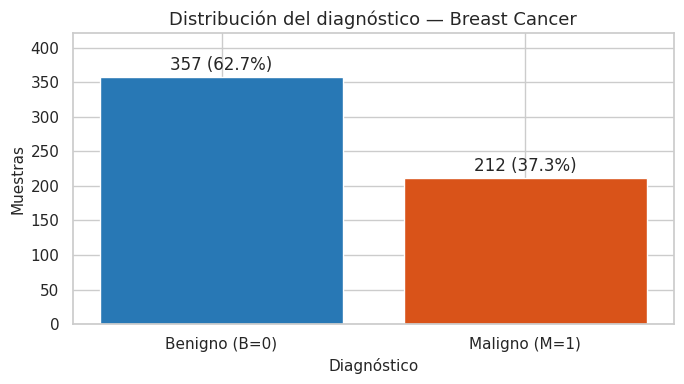

In [6]:
# 2.1 — frecuencias absolutas y relativas del diagnóstico.
from IPython.display import display

if not X.index.equals(y.index) or set(y.unique()) != {0, 1}:
    raise ValueError("EDA requiere X/y alineados y ambas clases: 0=B, 1=M.")
_etiquetas_eda = {0: "Benigno (B=0)", 1: "Maligno (M=1)"}
_colores_eda = {0: "#2878B5", 1: "#D95319"}
_conteos_eda = y.value_counts().reindex([0, 1], fill_value=0)
resumen_clases_eda = pd.DataFrame({
    "diagnostico": [_etiquetas_eda[c] for c in (0, 1)],
    "conteo": _conteos_eda.to_numpy(),
    "porcentaje": 100 * _conteos_eda.to_numpy() / len(y),
})
display(resumen_clases_eda.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
_barras_eda = ax.bar(resumen_clases_eda["diagnostico"], resumen_clases_eda["conteo"],
                     color=[_colores_eda[c] for c in (0, 1)])
for barra, porcentaje in zip(_barras_eda, resumen_clases_eda["porcentaje"]):
    ax.annotate(f"{int(barra.get_height())} ({porcentaje:.1f}%)",
                (barra.get_x() + barra.get_width()/2, barra.get_height()),
                xytext=(0, 5), textcoords="offset points", ha="center")
ax.set(title="Distribución del diagnóstico — Breast Cancer", ylabel="Muestras", xlabel="Diagnóstico")
ax.set_ylim(0, _conteos_eda.max() * 1.18)
fig.tight_layout()
plt.show()
# EDA descriptivo del conjunto disponible: no se modifica X/y, no se seleccionan
# variables ni hiperparámetros con estas salidas, que incluyen futuras filas de test.


### 2.2. Estadísticas descriptivas y distribución de predictores

Las cuatro variables representativas no presentan ausencias y las medianas globales son inferiores a sus medias, especialmente para `area_mean` (mediana 551,1; media 654,89), coherente con una cola hacia valores grandes. El criterio de 1,5 IQR marca 25 observaciones extremas en área, 18 en concavidad, 14 en radio y 7 en textura; son observaciones inusuales según una regla descriptiva, no errores confirmados.

Al separar por diagnóstico, las medianas malignas superan a las benignas en los cuatro casos: `radius_mean` 17,325 frente a 12,200; `area_mean` 932,0 frente a 458,4; `texture_mean` 21,46 frente a 17,39; y `concavity_mean` 0,1513 frente a 0,0371. La diferencia es particularmente marcada para tamaño y concavidad. Los histogramas muestran solapamiento entre las distribuciones y no permiten observar una separación perfecta mediante un único umbral simple. Son asociaciones descriptivas en la muestra, no efectos causales ni pruebas de significancia.

Estadísticos descriptivos de las variables representativas:


,count,mean,std,50%,min,max,ausentes,fuera_1_5_IQR
Predictor representativo,,,,,,,,
radius_mean,569.0,14.1273,3.5240,13.3700,6.981,28.1100,0,14
area_mean,569.0,654.8891,351.9141,551.1000,143.500,2501.0000,0,25
texture_mean,569.0,19.2896,4.3010,18.8400,9.710,39.2800,0,7
concavity_mean,569.0,0.0888,0.0797,0.0615,0.000,0.4268,0,18


,count,mean,std,min,25%,50%,75%,max,ausentes,fuera_1_5_IQR
radius_mean,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100,0,14
texture_mean,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800,0,7
perimeter_mean,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000,0,13
area_mean,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000,0,25
smoothness_mean,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634,0,6
compactness_mean,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454,0,16
concavity_mean,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268,0,18
concave points_mean,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012,0,10
symmetry_mean,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040,0,15
fractal_dimension_mean,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974,0,15


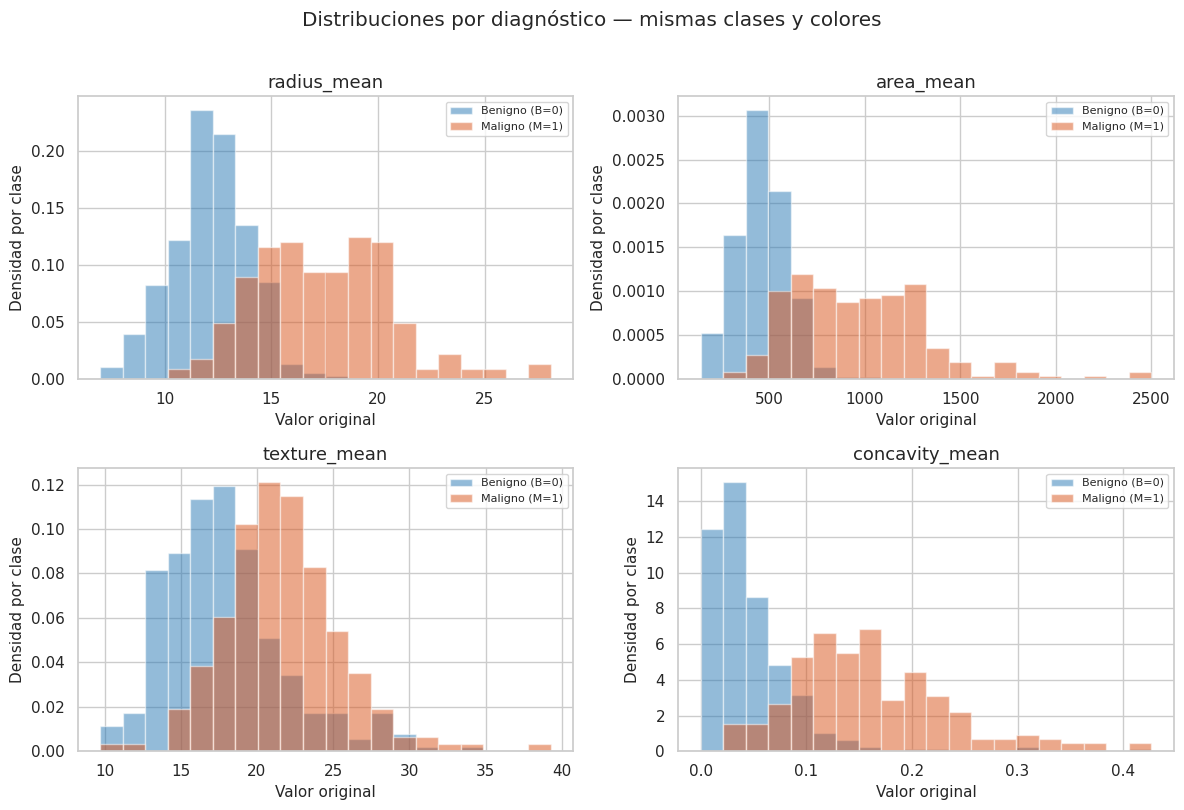

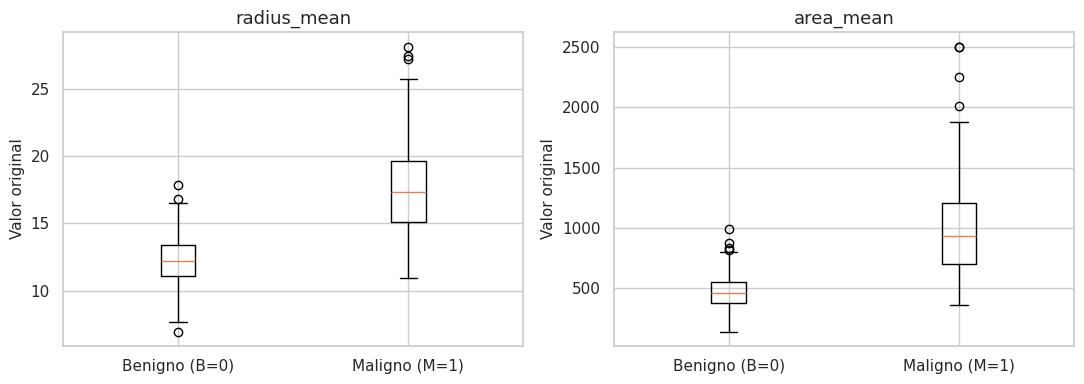

,radius_mean,area_mean,texture_mean,concavity_mean
diagnosis,,,,
Benigno (B=0),12.200,458.4,17.39,0.0371
Maligno (M=1),17.325,932.0,21.46,0.1513


In [7]:
# 2.2 — rangos, distribuciones y diferencias entre diagnósticos.
from IPython.display import HTML, display
# Resolver ambas fuentes permitidas: nombres del CSV y nombres de sklearn.
def _columna_eda(nombre_csv, nombre_sklearn):
    for nombre in (nombre_csv, nombre_sklearn):
        if nombre in X.columns:
            return nombre
    raise KeyError(f"No se encontró {nombre_csv} ni {nombre_sklearn} en X.")

variables_eda = [
    _columna_eda("radius_mean", "mean radius"),
    _columna_eda("area_mean", "mean area"),
    _columna_eda("texture_mean", "mean texture"),
    _columna_eda("concavity_mean", "mean concavity"),
]
resumen_predictoras_eda = X.describe().T
_q1_eda, _q3_eda = X.quantile(0.25), X.quantile(0.75)
_iqr_eda = _q3_eda - _q1_eda
_extremos_eda = X.lt(_q1_eda - 1.5*_iqr_eda) | X.gt(_q3_eda + 1.5*_iqr_eda)
resumen_predictoras_eda["ausentes"] = X.isna().sum()
resumen_predictoras_eda["fuera_1_5_IQR"] = _extremos_eda.sum()
columnas_resumen_eda = ["count", "mean", "std", "50%", "min", "max", "ausentes", "fuera_1_5_IQR"]
resumen_representativo_eda = resumen_predictoras_eda.loc[variables_eda, columnas_resumen_eda]
resumen_representativo_eda.index.name = "Predictor representativo"
print("Estadísticos descriptivos de las variables representativas:")
display(resumen_representativo_eda.round(4))
tabla_completa_eda_html = resumen_predictoras_eda.round(4).to_html(escape=True)
display(HTML(
    "<details><summary>Ver estadísticos de los 30 predictores</summary>"
    + tabla_completa_eda_html
    + "</details>"
))

# Radio y área describen tamaño; textura y concavidad aportan otras propiedades.
# Se conservan unidades originales, sin mezclar escalas en un mismo eje vertical.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, columna in zip(axes.ravel(), variables_eda):
    _valores_eda = X[columna].dropna()
    if _valores_eda.empty:
        ax.set_title(f"{columna}: sin valores observados")
        continue
    _bins_eda = np.histogram_bin_edges(_valores_eda, bins=20)
    for clase in (0, 1):
        valores = X.loc[y.eq(clase), columna].dropna()
        if not valores.empty:
            ax.hist(valores, bins=_bins_eda, density=True, alpha=0.5,
                    color=_colores_eda[clase], label=_etiquetas_eda[clase])
    ax.set(title=columna, xlabel="Valor original", ylabel="Densidad por clase")
    ax.legend(fontsize=8)
fig.suptitle("Distribuciones por diagnóstico — mismas clases y colores", y=1.01)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, columna in zip(axes, variables_eda[:2]):
    ax.boxplot([X.loc[y.eq(c), columna].dropna().to_numpy() for c in (0, 1)])
    ax.set_xticks([1, 2], [_etiquetas_eda[c] for c in (0, 1)])
    ax.set(title=columna, ylabel="Valor original")
fig.tight_layout()
plt.show()

medianas_por_diagnostico_eda = X[variables_eda].groupby(y).median().reindex([0, 1])
display(medianas_por_diagnostico_eda.rename(index=_etiquetas_eda).round(4))


### 2.3. Correlación y posibles redundancias

La matriz de Pearson y los diez pares principales revelan redundancia marcada entre mediciones de tamaño: `radius_mean`–`perimeter_mean` alcanza r = 0,9979; `radius_mean`–`area_mean`, r = 0,9874; y `radius_worst`–`perimeter_worst`, r = 0,9937. Las medidas “mean” y “worst” de tamaño también se asocian fuertemente (por ejemplo, `perimeter_mean`–`perimeter_worst`, r = 0,9704). Por tanto, varios predictores aportan señales parcialmente compartidas. En modelos lineales, esta colinealidad puede volver inestables o difíciles de atribuir los coeficientes individuales; en Random Forest, puede repartir la importancia entre variables sustitutas. La correlación de Pearson resume asociación lineal, no causalidad, y aquí se usa para interpretar, no para eliminar características.

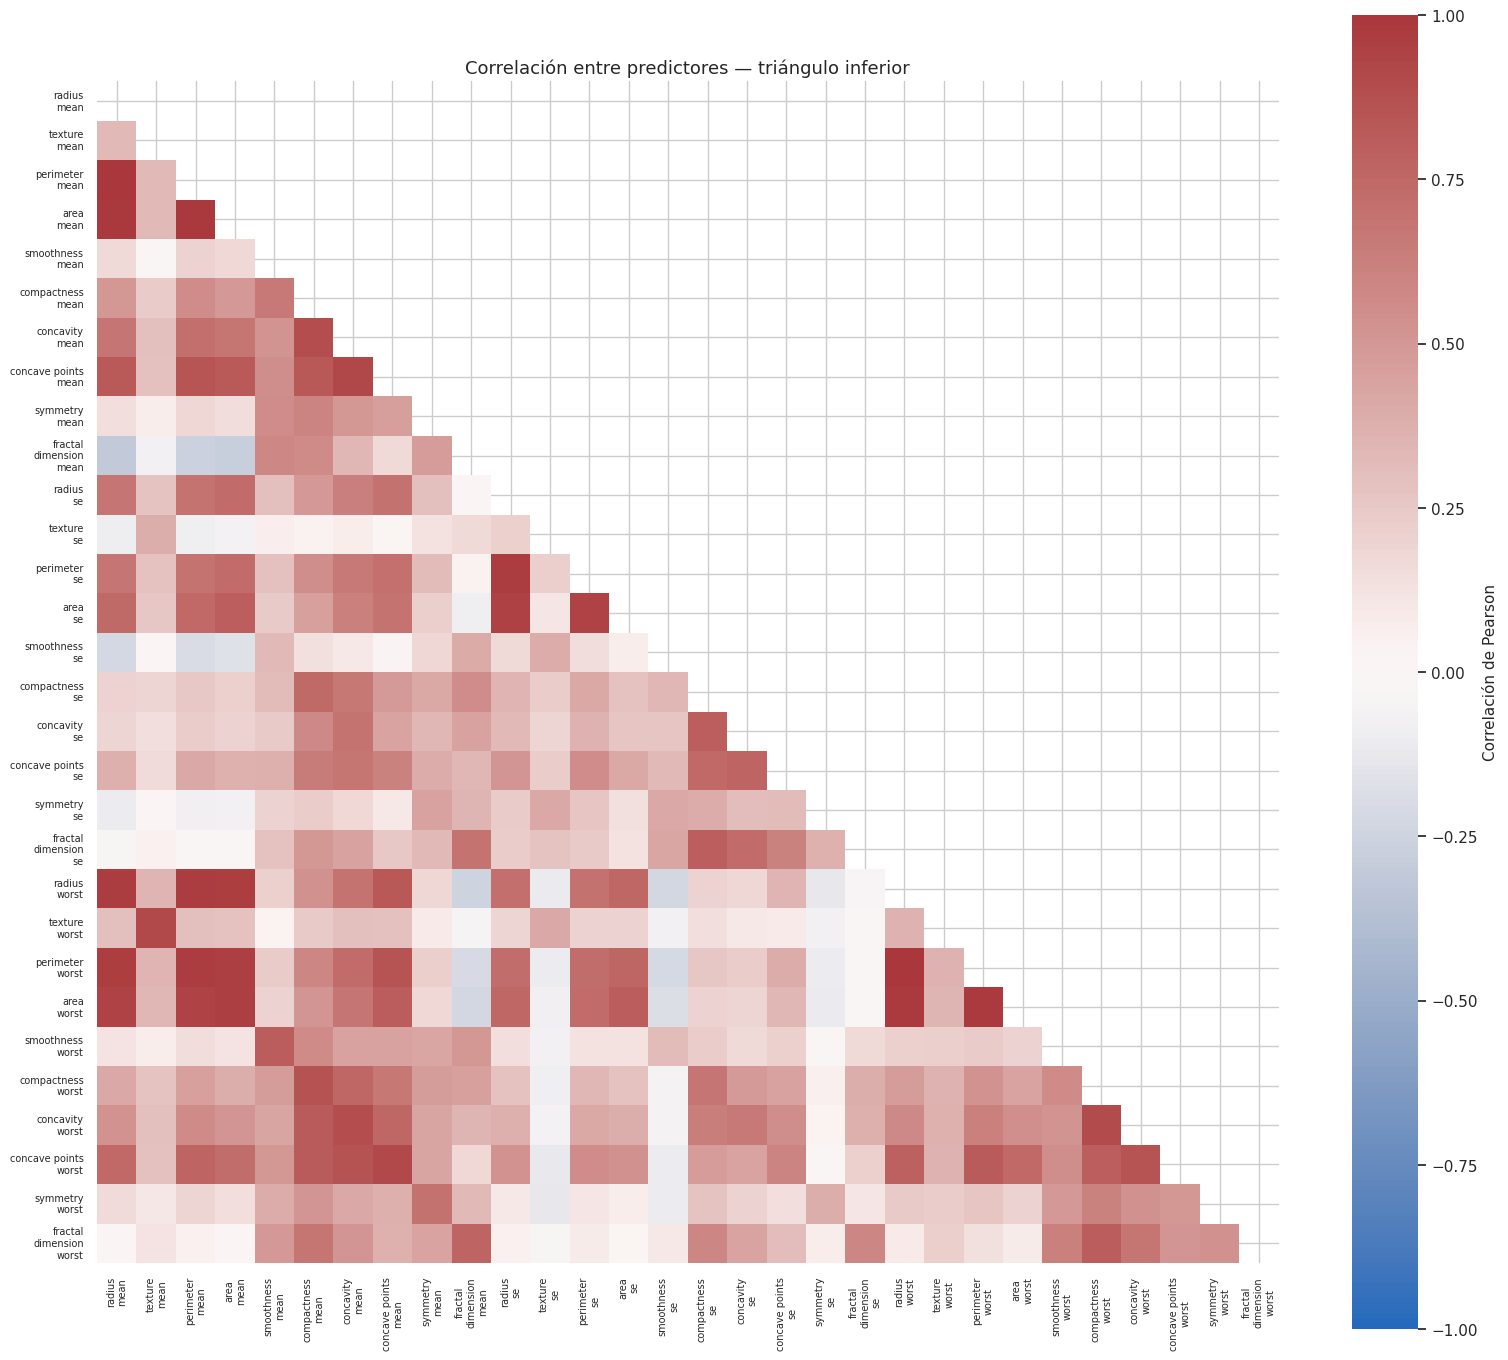

Diez pares con mayor correlación absoluta; sin diagonal ni pares duplicados:


,variable_1,variable_2,correlacion,correlacion_absoluta
0,radius_mean,perimeter_mean,0.9979,0.9979
1,radius_worst,perimeter_worst,0.9937,0.9937
2,radius_mean,area_mean,0.9874,0.9874
3,perimeter_mean,area_mean,0.9865,0.9865
4,radius_worst,area_worst,0.9840,0.9840
5,perimeter_worst,area_worst,0.9776,0.9776
6,radius_se,perimeter_se,0.9728,0.9728
7,perimeter_mean,perimeter_worst,0.9704,0.9704
8,radius_mean,radius_worst,0.9695,0.9695
9,perimeter_mean,radius_worst,0.9695,0.9695


In [8]:
# 2.3 — correlación de las 30 características, sin eliminarlas.
correlacion_eda = X.corr(method="pearson")
fig, ax = plt.subplots(figsize=(16, 14))
_mascara_eda = np.triu(np.ones(correlacion_eda.shape, dtype=bool))
sns.heatmap(correlacion_eda, mask=_mascara_eda, cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"label": "Correlación de Pearson"})
ax.set_title("Correlación entre predictores — triángulo inferior")
etiquetas_corr_eda = [nombre.replace("_", "\n") for nombre in correlacion_eda.columns]
ax.set_xticklabels(etiquetas_corr_eda, rotation=90, fontsize=7)
ax.set_yticklabels(etiquetas_corr_eda, rotation=0, fontsize=7)
fig.tight_layout()
plt.show()

_triangulo_eda = np.triu(np.ones(correlacion_eda.shape, dtype=bool), k=1)
pares_correlacion_eda = (
    correlacion_eda.where(_triangulo_eda).stack().rename("correlacion")
    .rename_axis(["variable_1", "variable_2"]).reset_index()
)
pares_correlacion_eda["correlacion_absoluta"] = pares_correlacion_eda["correlacion"].abs()
pares_correlacion_eda = pares_correlacion_eda.sort_values(
    "correlacion_absoluta", ascending=False, kind="stable").reset_index(drop=True)
print("Diez pares con mayor correlación absoluta; sin diagonal ni pares duplicados:")
display(pares_correlacion_eda.head(10).round(4))


## 3. Preparación y preprocesamiento

### 3.1. División estratificada entrenamiento/prueba

La estratificación produjo 455 observaciones de entrenamiento (170 malignas; 37,36 %) y 114 de prueba (42 malignas; 36,84 %), frente al 37,26 % maligno del conjunto completo. Esta proximidad reduce el cambio de composición entre particiones y hace más comparable la evaluación, aunque una única partición todavía puede variar con otra semilla o muestra.

In [9]:
# 3.1 División estratificada entrenamiento/prueba
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from IPython.display import display

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

if "X" not in globals() or "y" not in globals():
    raise NameError("Las variables 'X' e 'y' deben estar definidas antes de particionar (sección 1.3).")

# Partición estratificada 80% train / 20% test con semilla global
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Validaciones defensivas de consistencia
if len(X_train) != len(y_train):
    raise ValueError("X_train e y_train no tienen la misma cantidad de filas.")
if len(X_test) != len(y_test):
    raise ValueError("X_test e y_test no tienen la misma cantidad de filas.")
if X_train.shape[1] != 30 or X_test.shape[1] != 30:
    raise ValueError(f"Se esperaban 30 predictores; train={X_train.shape[1]}, test={X_test.shape[1]}")

# Resumen detallado de estratificación
resumen_particion = pd.DataFrame({
    "Total muestras": [len(y), len(y_train), len(y_test)],
    "Porcentaje split (%)": [100.0, len(y_train) / len(y) * 100, len(y_test) / len(y) * 100],
    "Benigno (0)": [int((y == 0).sum()), int((y_train == 0).sum()), int((y_test == 0).sum())],
    "Maligno (1)": [int((y == 1).sum()), int((y_train == 1).sum()), int((y_test == 1).sum())],
    "Prop. Maligno (%)": [
        (y == 1).mean() * 100,
        (y_train == 1).mean() * 100,
        (y_test == 1).mean() * 100
    ]
}, index=["Dataset completo", "Entrenamiento (train)", "Prueba (test)"])

print("Partición estratificada 80/20 completada con éxito:")
display(resumen_particion.round(2))
print("El conjunto de prueba (test) queda estrictamente reservado para la evaluación final en la sección 5.")


Partición estratificada 80/20 completada con éxito:


,Total muestras,Porcentaje split (%),Benigno (0),Maligno (1),Prop. Maligno (%)
Dataset completo,569,100.00,357,212,37.26
Entrenamiento (train),455,79.96,285,170,37.36
Prueba (test),114,20.04,72,42,36.84


El conjunto de prueba (test) queda estrictamente reservado para la evaluación final en la sección 5.


### 3.2. Escalamiento e imputación

En esta ejecución no hubo ausentes en train ni test, por lo que la imputación condicional no se activó. `StandardScaler` se ajustó sobre las 455 observaciones de entrenamiento; las medias escaladas son aproximadamente 0 y la varianza muestral media es 1,0022 (la pequeña diferencia respecto de 1 se debe a la convención de varianza muestral). La transformación es pertinente para las distancias de KNN y la frontera de SVM, además de la regularización logística; los árboles conservaron las mediciones originales.

In [10]:
# 3.2 Escalamiento e imputación condicional sin fuga de información
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from IPython.display import display

if "X" not in globals():
    raise NameError("X no está definida; se requiere su definición en la sección 1.3.")
if "X_train" not in globals() or "X_test" not in globals():
    raise NameError("X_train y X_test no están definidas; se requiere la partición de la sección 3.1.")

# 1. Preservar copia de entrenamiento directamente desde X original usando los índices de entrenamiento:
# La copia se obtiene de X para mantener los predictores originales para validación cruzada.
X_train_cv = X.loc[X_train.index].copy()
X_test_orig = X.loc[X_test.index].copy()

# 2. Estrategia condicional de imputación para los modelos de árboles y ajuste final:
# Si hubiera valores ausentes, se imputan con la mediana calculada únicamente en entrenamiento.
# Si aparecen ausentes en train o test, se imputan usando la mediana calculada solo en X_train_cv,
# garantizando compatibilidad con modelos de árboles (Decision Tree y Random Forest) que usan X_train directamente.
conteo_ausentes_train = int(X_train_cv.isna().sum().sum())
conteo_ausentes_test = int(X_test_orig.isna().sum().sum())
imputador = None

if conteo_ausentes_train > 0 or conteo_ausentes_test > 0:
    imputador = SimpleImputer(strategy="median")
    imputador.fit(X_train_cv)
    X_train = pd.DataFrame(
        imputador.transform(X_train_cv),
        columns=X_train_cv.columns,
        index=X_train_cv.index
    )
    X_test = pd.DataFrame(
        imputador.transform(X_test_orig),
        columns=X_test_orig.columns,
        index=X_test_orig.index
    )
    print(f"Imputación condicional aplicada (SimpleImputer, mediana): {conteo_ausentes_train} ausentes en train, {conteo_ausentes_test} en test.")
else:
    X_train = X_train_cv.copy()
    X_test = X_test_orig.copy()
    print("Sin valores ausentes en X_train ni X_test. No fue necesario aplicar imputación activa.")

# 3. Justificación del escalamiento:
# - KNN se basa en distancia euclidiana: predictores con gran rango numérico (ej. area_mean ~ 2500) dominarían frente a rangos pequeños (ej. smoothness ~ 0.1).
# - SVM con kernel RBF o lineal maximiza márgenes geométricos; variables con escalas dispares distorsionan los hiperplanos.
# - Regresión Logística regularizada aplica penalizaciones L1/L2 por igual, perjudicando injustamente a predictores con menor escala.
# - Modelos de ensamble/árboles (Decision Tree y Random Forest) son invariantes a transformaciones monótonas y usan X_train y X_test originales (ya limpios/imputados).

escalador = StandardScaler()

# El escalador se ajusta únicamente sobre X_train.
escalador.fit(X_train)

# Transformación conservando DataFrame con nombres de columnas e índices correspondientes
X_train_scaled = pd.DataFrame(
    escalador.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    escalador.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Validación de propiedades estadísticas en entrenamiento (media ~ 0, varianza ~ 1)
medias_train = X_train_scaled.mean()
varianzas_train = X_train_scaled.var()

print("Escalamiento mediante StandardScaler:")
print(f" - Copia X_train_cv generada desde X original para Pipeline en validación cruzada: {X_train_cv.shape}")
print(f" - Escalador ajustado exclusivamente con X_train ({X_train.shape[0]} observaciones).")
print(f" - Forma de X_train_scaled: {X_train_scaled.shape}")
print(f" - Forma de X_test_scaled:  {X_test_scaled.shape}")
print(f" - Promedio de medias en train escalado:     {medias_train.mean():.4f} (teórico: 0)")
print(f" - Promedio de varianzas en train escalado:  {varianzas_train.mean():.4f} (teórico: 1)")
print(" - Variables X_train y X_test (sin escalar, compatibles con árboles) preservadas.")


Sin valores ausentes en X_train ni X_test. No fue necesario aplicar imputación activa.
Escalamiento mediante StandardScaler:
 - Copia X_train_cv generada desde X original para Pipeline en validación cruzada: (455, 30)
 - Escalador ajustado exclusivamente con X_train (455 observaciones).
 - Forma de X_train_scaled: (455, 30)
 - Forma de X_test_scaled:  (114, 30)
 - Promedio de medias en train escalado:     0.0000 (teórico: 0)
 - Promedio de varianzas en train escalado:  1.0022 (teórico: 1)
 - Variables X_train y X_test (sin escalar, compatibles con árboles) preservadas.


### 3.3. Comprobaciones de preparación antes de entrenar

Las comprobaciones registran matrices de 455 × 30 para entrenamiento y 114 × 30 para prueba, etiquetas con 170 casos malignos en train y 42 en test, y cero valores NaN o infinitos. Esto acredita consistencia estructural y numérica antes del ajuste; por sí solo, no constituye una auditoría completa de fuga de información ni evidencia de generalización.

In [11]:
# 3.3 Comprobaciones de preparación antes de entrenar
import numpy as np

# 1. Comprobación de dimensiones idénticas
if X_train_scaled.shape != X_train.shape:
    raise AssertionError(f"Dimensión inconsistente en train: {X_train_scaled.shape} vs {X_train.shape}")
if X_test_scaled.shape != X_test.shape:
    raise AssertionError(f"Dimensión inconsistente en test: {X_test_scaled.shape} vs {X_test.shape}")
if "X_train_cv" not in globals() or X_train_cv.shape != X_train.shape:
    raise AssertionError("X_train_cv no está definida o sus dimensiones difieren de X_train.")

# 2. Ausencia de NaN e infinitos en arreglos de entrenamiento y prueba (originales y escalados)
# Confirma que la estrategia de imputación condicional de 3.2 garantizó matrices libres de ausentes
for nombre_arr, arr in [
    ("X_train", X_train.to_numpy(dtype=float)),
    ("X_test", X_test.to_numpy(dtype=float)),
    ("X_train_scaled", X_train_scaled.to_numpy(dtype=float)),
    ("X_test_scaled", X_test_scaled.to_numpy(dtype=float)),
]:
    if not np.isfinite(arr).all():
        raise ValueError(f"{nombre_arr} contiene valores NaN o infinitos tras el preprocesamiento.")

# 3. Validación de etiquetas binarias respetando 1 = M (maligno) y 0 = B (benigno)
if not set(np.unique(y_train)).issubset({0, 1}) or not set(np.unique(y_test)).issubset({0, 1}):
    raise ValueError("Las etiquetas y_train e y_test deben contener únicamente los valores {0, 1}.")

# 4. Estado del flujo de imputación
estado_imputacion = "Aplicada en 3.2" if "imputador" in globals() and imputador is not None else "No requerida (0 ausentes)"

print("============================================================")
print("✓ VERIFICACIONES DE PREPROCESAMIENTO COMPLETADAS CON ÉXITO")
print("============================================================")
print(f"- Dimensiones de entrenamiento: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"- Dimensiones de prueba:        X_test {X_test.shape}, y_test {y_test.shape}")
print(f"- Respaldo para CV (Pipeline):  X_train_cv {X_train_cv.shape}")
print(f"- Flujo de imputación:          {estado_imputacion}")
print("- Integridad numérica:          0 valores NaN y 0 infinitos en datos originales y escalados.")
print(f"- Codificación de clases:       1 = M (maligno: {(y_train == 1).sum()} train / {(y_test == 1).sum()} test), 0 = B (benigno)")
print("- Datos listos para modelos lineales/distancias (escalados) y modelos de árboles (sin escalar).")


✓ VERIFICACIONES DE PREPROCESAMIENTO COMPLETADAS CON ÉXITO
- Dimensiones de entrenamiento: X_train (455, 30), y_train (455,)
- Dimensiones de prueba:        X_test (114, 30), y_test (114,)
- Respaldo para CV (Pipeline):  X_train_cv (455, 30)
- Flujo de imputación:          No requerida (0 ausentes)
- Integridad numérica:          0 valores NaN y 0 infinitos en datos originales y escalados.
- Codificación de clases:       1 = M (maligno: 170 train / 42 test), 0 = B (benigno)
- Datos listos para modelos lineales/distancias (escalados) y modelos de árboles (sin escalar).


## 4. Modelos de clasificación

La evaluación posterior muestra diferencias relevantes pese a que los cinco modelos usan la misma partición: SVM y Random Forest obtuvieron el mayor Accuracy observado (0,9737), mientras que el árbol quedó en 0,9123. La comparación entre familias debe considerar también Recall_M y el tipo de error, pues el Accuracy agregado no refleja por sí solo cuántos malignos quedaron sin detectar.

### 4.1. Regresión logística

La regresión logística convergió en 20 iteraciones con los predictores escalados. En test alcanzó Accuracy 0,9649 y Recall_M 0,9286 (3 falsos negativos), con ROC-AUC 0,9960. Es un resultado competitivo en esta partición; la correlación alta entre medidas de tamaño aconseja no atribuir el peso predictivo a un coeficiente aislado.

In [12]:
# 4.1 — regresión logística con entrada escalada compartida.
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

_requeridas_lr = ("X_train", "y_train", "X_train_scaled", "modelos_entrenados", "tipo_entrada")
_faltantes_lr = [nombre for nombre in _requeridas_lr if nombre not in globals()]
if _faltantes_lr:
    raise RuntimeError("Dependencias requeridas para 4.1 ausentes: " + ", ".join(_faltantes_lr))
if not X_train.index.equals(y_train.index) or set(y_train.unique()) != {0, 1}:
    raise ValueError("X_train/y_train deben estar alineados y respetar M=1/B=0.")
if np.shape(X_train_scaled) != X_train.shape or not np.isfinite(np.asarray(X_train_scaled)).all():
    raise ValueError("X_train_scaled debe conservar la forma de train y no contener NaN/inf.")

# C=1.0 es una configuración inicial fija; no se optimiza con el conjunto de prueba.
# lbfgs aplica regularización L2 por defecto. No se cambia el escalador de Brickzon.
regresion_logistica = LogisticRegression(
    C=1.0, solver="lbfgs", max_iter=5000, random_state=RANDOM_STATE,
)
# Una falta de convergencia detiene el registro; no se presenta como ajuste correcto.
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    regresion_logistica.fit(X_train_scaled, y_train)

modelos_entrenados["Regresión logística"] = regresion_logistica
tipo_entrada["Regresión logística"] = "escalado"
print("Regresión logística ajustada exclusivamente con entrenamiento escalado.")
print("C=1.0 | solver=lbfgs | max_iter=5000 | iteraciones:", regresion_logistica.n_iter_.tolist())
print("Clases del estimador:", regresion_logistica.classes_.tolist(), "(1=M)")
# Línea base: estima probabilidades y una frontera lineal con coeficientes
# interpretables de forma condicional. La correlación entre variables limita
# atribuir importancia individual. Predicciones y métricas de test se centralizan en 5.1.


Regresión logística ajustada exclusivamente con entrenamiento escalado.
C=1.0 | solver=lbfgs | max_iter=5000 | iteraciones: [20]
Clases del estimador: [0, 1] (1=M)


### 4.2. K vecinos más cercanos (KNN)

La validación cruzada de cinco pliegues en entrenamiento favoreció k = 7 (F1 medio 0,9563), aunque los valores para k = 3 y k = 9 fueron cercanos (0,9539 y 0,9537). La diferencia pequeña entre estos promedios no demuestra que k = 7 sea superior de forma estadísticamente significativa. En test, KNN alcanzó Accuracy 0,9561, Recall_M 0,9048 y cuatro falsos negativos, por debajo de los tres modelos líderes en detección maligna.

In [13]:
# 4.2 K vecinos más cercanos (KNN)
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

if "modelos_entrenados" not in globals():
    modelos_entrenados = {}
if "tipo_entrada" not in globals():
    tipo_entrada = {}
if "X_train_cv" not in globals():
    raise NameError("La variable 'X_train_cv' no está definida. Se requiere la matriz de entrenamiento original preparada en 3.2.")

# Justificación del escalamiento:
# KNN asigna etiquetas según la distancia en el espacio de características.
# Con datos escalados, cada una de las 30 propiedades celulares contribuye proporcionalmente a la métrica de distancia.

# Selección de hiperparámetro k mediante validación cruzada (5-Fold CV)
# Para evitar cualquier fuga de información entre pliegues (tanto de imputación como de escala),
# se utiliza un Pipeline con SimpleImputer y StandardScaler, evaluado sobre X_train_cv (datos originales previos a imputación).
k_candidatos = [3, 5, 7, 9, 11]
scores_cv = {}

for k in k_candidatos:
    pipe_knn = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, weights="uniform", metric="minkowski", p=2))
    ])

    # Se evalúa sobre X_train_cv; el Pipeline imputa y escala internamente dentro de cada pliegue
    score_f1 = cross_val_score(pipe_knn, X_train_cv, y_train, cv=5, scoring="f1").mean()
    scores_cv[k] = score_f1

k_optimo = max(scores_cv, key=scores_cv.get)
print("Selección de hiperparámetro K mediante validación cruzada (Pipeline [Imputer + Scaler] sobre X_train_cv):")
for k, score in scores_cv.items():
    marca = " <-- k seleccionado (mejor F1 en CV)" if k == k_optimo else ""
    print(f" - k={k}: F1 medio en CV = {score:.4f}{marca}")

# Ajuste final del modelo KNN sobre X_train_scaled.
modelo_knn = KNeighborsClassifier(n_neighbors=k_optimo, weights="uniform", metric="minkowski", p=2)
modelo_knn.fit(X_train_scaled, y_train)

# Registro del estimador y el tipo de matriz de entrada.
modelos_entrenados["KNN"] = modelo_knn
tipo_entrada["KNN"] = "escalado"

print(f"\nModelo KNN final ajustado exitosamente con n_neighbors={k_optimo} sobre X_train_scaled.")


Selección de hiperparámetro K mediante validación cruzada (Pipeline [Imputer + Scaler] sobre X_train_cv):
 - k=3: F1 medio en CV = 0.9539
 - k=5: F1 medio en CV = 0.9475
 - k=7: F1 medio en CV = 0.9563 <-- k seleccionado (mejor F1 en CV)
 - k=9: F1 medio en CV = 0.9537
 - k=11: F1 medio en CV = 0.9409

Modelo KNN final ajustado exitosamente con n_neighbors=7 sobre X_train_scaled.


### 4.3. Máquinas de vectores de soporte (SVM)

La configuración RBF fija obtuvo F1 medio de validación cruzada 0,9641 en entrenamiento y usó 107 vectores de soporte. En la prueba alcanzó Accuracy 0,9737, Precision_M 1,0000, Recall_M 0,9286 (3 falsos negativos) y ROC-AUC 0,9947. La precisión perfecta observada significa que las predicciones malignas emitidas en esta partición fueron correctas; no implica que se detectaran todos los malignos ni que el desempeño se mantenga fuera de ella.

In [14]:
# 4.3 Máquinas de vectores de soporte (SVM)
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42
if "modelos_entrenados" not in globals():
    modelos_entrenados = {}
if "tipo_entrada" not in globals():
    tipo_entrada = {}
if "X_train_cv" not in globals():
    raise NameError("La variable 'X_train_cv' no está definida. Se requiere la matriz de entrenamiento original preparada en 3.2.")

# Configuración del estimador SVC:
# - kernel='rbf': proyecta a un espacio de Hilbert para capturar límites de decisión no lineales.
# - C=1.0: equilibrio estándar entre margen amplio y penalización de errores de clasificación.
# - probability=True: habilita predict_proba para curvas ROC y calibración probabilística.
# - decision_function: disponible de forma nativa para puntuaciones continuas de discriminación de clase 1.
# - random_state=RANDOM_STATE: garantiza reproducibilidad en el ajuste de probabilidades internas.

# Validación cruzada (5-Fold CV) sin fuga de datos usando Pipeline con SimpleImputer y StandardScaler sobre X_train_cv
pipe_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(C=1.0, kernel="rbf", gamma="scale", probability=True, random_state=RANDOM_STATE))
])

f1_cv_svm = cross_val_score(pipe_svm, X_train_cv, y_train, cv=5, scoring="f1").mean()

# Ajuste final del modelo SVM sobre X_train_scaled.
modelo_svm = SVC(
    C=1.0,
    kernel="rbf",
    gamma="scale",
    probability=True,
    random_state=RANDOM_STATE
)
modelo_svm.fit(X_train_scaled, y_train)

# Registro del estimador y el tipo de matriz de entrada.
modelos_entrenados["SVM"] = modelo_svm
tipo_entrada["SVM"] = "escalado"

print("Modelo SVM ajustado exitosamente:")
print(f" - Hiperparámetros: kernel='{modelo_svm.kernel}', C={modelo_svm.C}, gamma='{modelo_svm.gamma}'")
print(f" - Vectores de soporte totales: {len(modelo_svm.support_)} ({modelo_svm.n_support_} por clase [B, M])")
print(f" - F1 medio en validación cruzada interna (Pipeline [Imputer + Scaler] sobre X_train_cv): {f1_cv_svm:.4f}")
print(" - Puntuación continua disponible para Curva ROC (5.4): decision_function y predict_proba(X)[:, 1]")


Modelo SVM ajustado exitosamente:
 - Hiperparámetros: kernel='rbf', C=1.0, gamma='scale'
 - Vectores de soporte totales: 107 ([50 57] por clase [B, M])
 - F1 medio en validación cruzada interna (Pipeline [Imputer + Scaler] sobre X_train_cv): 0.9641
 - Puntuación continua disponible para Curva ROC (5.4): decision_function y predict_proba(X)[:, 1]


### 4.4. Árbol de decisión

El árbol ajustado alcanzó profundidad 4. En test presentó el menor Accuracy (0,9123), Recall_M (0,8095) y ROC-AUC (0,8770) de los cinco; clasificó como benignos 8 de los 42 malignos. La estructura de reglas relativamente compacta no compensó aquí la mayor omisión de casos malignos, y el resultado pertenece a esta muestra de prueba.

In [15]:
# Limitar la profundidad reduce el riesgo de sobreajuste.
arbol_decision = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
arbol_decision.fit(X_train, y_train)

modelos_entrenados["Árbol de decisión"] = arbol_decision
tipo_entrada["Árbol de decisión"] = "original"

print(f"Árbol de decisión ajustado. Profundidad obtenida: {arbol_decision.get_depth()}.")

Árbol de decisión ajustado. Profundidad obtenida: 4.


### 4.5. Random Forest

El bosque de 100 árboles obtuvo en test el mayor ROC-AUC (0,9980), junto con SVM el mayor Accuracy (0,9737), Precision_M (1,0000) y F1_M (0,9630); su Recall_M fue 0,9286 (3 falsos negativos). Estas cifras hacen que encabece el orden académico aplicado más adelante, pero su diferencia respecto de SVM es pequeña y no se ha sometido a una prueba inferencial de comparación.

In [16]:
# Cada hoja debe tener al menos dos muestras de entrenamiento.
bosque_aleatorio = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
)
bosque_aleatorio.fit(X_train, y_train)

modelos_entrenados["Random Forest"] = bosque_aleatorio
tipo_entrada["Random Forest"] = "original"

print(
    f"Random Forest ajustado con {bosque_aleatorio.n_estimators} árboles "
    f"y un mínimo de {bosque_aleatorio.min_samples_leaf} muestras por hoja."
)
print(f"Importancias disponibles para {len(bosque_aleatorio.feature_importances_)} características.")

Random Forest ajustado con 100 árboles y un mínimo de 2 muestras por hoja.
Importancias disponibles para 30 características.


## 5. Evaluación de los modelos

### 5.1. Predicciones y cálculo centralizado de métricas

En la prueba común de 114 observaciones, Random Forest y SVM igualaron el mayor Accuracy (0,9737), precisión para malignidad (1,0000), Recall_M (0,9286) y F1_M (0,9630); difirieron en ROC-AUC (0,9980 frente a 0,9947). La regresión logística quedó cerca, con Accuracy 0,9649 y Recall_M 0,9286. KNN registró Recall_M 0,9048 y el árbol 0,8095. El baseline de predecir siempre la clase benigna acertaría 72/114 (0,6316), muy por debajo de los cinco modelos, pero esta comparación puntual no cuantifica incertidumbre ni prueba generalización.

In [17]:
NOMBRES_MODELOS = (
    "Regresión logística", "KNN", "SVM", "Árbol de decisión", "Random Forest"
)
COLUMNAS_RESULTADOS = ["Modelo", "Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"]


def _validar_contrato_evaluacion():
    requeridas = ("modelos_entrenados", "tipo_entrada", "X_test", "X_test_scaled", "y_test")
    faltantes = [nombre for nombre in requeridas if nombre not in globals()]
    if faltantes:
        raise RuntimeError("Faltan variables compartidas para evaluar: " + ", ".join(faltantes))
    if not isinstance(modelos_entrenados, dict) or not isinstance(tipo_entrada, dict):
        raise TypeError("modelos_entrenados y tipo_entrada deben ser diccionarios.")
    faltan_modelos = [n for n in NOMBRES_MODELOS if n not in modelos_entrenados]
    extras = [n for n in modelos_entrenados if n not in NOMBRES_MODELOS]
    if faltan_modelos or extras:
        raise ValueError(f"El registro de modelos no coincide con los cinco clasificadores. Faltan: {faltan_modelos}; extras: {extras}.")
    faltan_tipos = [n for n in NOMBRES_MODELOS if n not in tipo_entrada]
    extras_tipo = [n for n in tipo_entrada if n not in NOMBRES_MODELOS]
    if faltan_tipos or extras_tipo:
        raise ValueError(f"Registro de tipos incorrecto. Faltan: {faltan_tipos}; extras: {extras_tipo}.")
    invalidos = {n: tipo_entrada[n] for n in NOMBRES_MODELOS
                 if tipo_entrada[n] not in ("escalado", "original")}
    if invalidos:
        raise ValueError(f"Cada tipo debe ser 'escalado' u 'original'; valores inválidos: {invalidos}.")
    forma_original = np.shape(X_test)
    forma_escalada = np.shape(X_test_scaled)
    if len(forma_original) != 2 or len(forma_escalada) != 2:
        raise ValueError("X_test y X_test_scaled deben ser arreglos bidimensionales.")
    if forma_original != forma_escalada:
        raise ValueError("X_test y X_test_scaled deben tener las mismas dimensiones.")
    if forma_original[0] != len(y_test):
        raise ValueError("X_test, X_test_scaled y y_test deben tener la misma cantidad de filas.")
    clases_test = set(np.asarray(y_test).ravel().tolist())
    if not clases_test.issubset({0, 1}) or clases_test != {0, 1}:
        raise ValueError("y_test debe contener ambas clases codificadas como 0=B y 1=M.")


def _score_clase_maligna(modelo, X_eval):
    clases = np.asarray(getattr(modelo, "classes_", []))
    posiciones = np.flatnonzero(clases == 1)
    if len(posiciones) != 1:
        raise ValueError("El modelo debe exponer classes_ con la clase positiva 1=M.")
    if hasattr(modelo, "predict_proba"):
        probabilidades = np.asarray(modelo.predict_proba(X_eval))
        if probabilidades.ndim != 2 or probabilidades.shape[1] != len(clases):
            raise ValueError("predict_proba devolvió dimensiones incompatibles con classes_.")
        score = probabilidades[:, posiciones[0]]
    elif hasattr(modelo, "decision_function"):
        score = np.asarray(modelo.decision_function(X_eval))
        if score.ndim == 2:
            score = score[:, posiciones[0]]
        elif score.ndim == 1 and len(clases) == 2 and posiciones[0] == 0:
            # En SVC binario, score positivo corresponde a classes_[1].
            score = -score
        elif score.ndim != 1:
            raise ValueError("decision_function devolvió una forma no compatible.")
    else:
        raise TypeError("El modelo necesita predict_proba() o decision_function() para ROC-AUC.")
    score = np.asarray(score, dtype=float).ravel()
    if len(score) != len(y_test) or not np.isfinite(score).all():
        raise ValueError("Las puntuaciones ROC deben ser finitas y corresponder a todo y_test.")
    return score


_validar_contrato_evaluacion()
y_pred_por_modelo = {}
y_score_por_modelo = {}
filas_metricas = []

for nombre in NOMBRES_MODELOS:
    modelo = modelos_entrenados[nombre]
    X_eval = X_test_scaled if tipo_entrada[nombre] == "escalado" else X_test
    y_pred = np.asarray(modelo.predict(X_eval)).ravel()
    if len(y_pred) != len(y_test):
        raise ValueError(f"{nombre}: predict() no devolvió una predicción por fila de y_test.")
    clases_modelo = set(np.asarray(getattr(modelo, "classes_", [])).tolist())
    if clases_modelo != {0, 1} or not set(y_pred.tolist()).issubset({0, 1}):
        raise ValueError(f"{nombre}: classes_ debe ser {{0, 1}} y predict() debe respetar 0=B, 1=M.")
    score_m = _score_clase_maligna(modelo, X_eval)
    y_pred_por_modelo[nombre] = y_pred
    y_score_por_modelo[nombre] = score_m
    filas_metricas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_M": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall_M": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1_M": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, score_m),
    })

resultados_df = pd.DataFrame(filas_metricas, columns=COLUMNAS_RESULTADOS)
print("Métricas calculadas sobre el mismo conjunto de prueba para los cinco modelos.")
display(resultados_df.round(4))

Métricas calculadas sobre el mismo conjunto de prueba para los cinco modelos.


,Modelo,Accuracy,Precision_M,Recall_M,F1_M,ROC_AUC
0,Regresión logística,0.9649,0.9750,0.9286,0.9512,0.9960
1,KNN,0.9561,0.9744,0.9048,0.9383,0.9825
2,SVM,0.9737,1.0000,0.9286,0.9630,0.9947
3,Árbol de decisión,0.9123,0.9444,0.8095,0.8718,0.8770
4,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9980


### 5.2. Tabla comparativa y ordenamiento

El orden declarado prioriza Recall_M, luego F1_M y ROC-AUC. Random Forest y SVM empatan en Recall_M (0,9286) y F1_M (0,9630); el AUC ligeramente mayor del bosque (0,9980 vs. 0,9947) lo coloca primero. La regresión logística comparte el mismo Recall (0,9286) pero alcanza F1 0,9512; KNN obtiene 0,9048 y el árbol 0,8095. Como solo hay 42 malignos en test, un caso cambia el Recall en 1/42; estas diferencias son descriptivas, no una prueba de superioridad estadística. Además, elegir al ganador sobre este mismo conjunto de prueba introduce optimismo de selección en sus métricas.

In [18]:
import numpy as np
import pandas as pd
from IPython.display import display

columnas_comparacion = ["Modelo", "Recall_M", "F1_M", "ROC_AUC"]
modelos_esperados = {
    "Regresión logística", "KNN", "SVM", "Árbol de decisión", "Random Forest"
}
if "resultados_df" not in globals():
    raise NameError("resultados_df no está disponible; se requiere la evaluación de la sección 5.1.")
if not set(columnas_comparacion).issubset(resultados_df.columns):
    raise ValueError(f"resultados_df debe incluir: {columnas_comparacion}")
if len(resultados_df) != 5 or set(resultados_df["Modelo"]) != modelos_esperados:
    raise ValueError("resultados_df debe contener exactamente los cinco clasificadores acordados.")

comparacion = resultados_df[columnas_comparacion].copy()
metricas_comparacion = ["Recall_M", "F1_M", "ROC_AUC"]
comparacion[metricas_comparacion] = comparacion[metricas_comparacion].apply(pd.to_numeric, errors="raise")
if not np.isfinite(comparacion[metricas_comparacion].to_numpy(dtype=float)).all():
    raise ValueError("Las métricas comparativas deben ser numéricas y finitas.")
comparacion = comparacion.sort_values(
    ["Recall_M", "F1_M", "ROC_AUC"], ascending=False, kind="mergesort"
).reset_index(drop=True)
comparacion.insert(0, "Orden académico", np.arange(1, len(comparacion) + 1))
display(comparacion.round(4))
print("Orden descriptivo: Recall_M, F1_M y ROC_AUC; los valores completos están en 5.1.")

,Orden académico,Modelo,Recall_M,F1_M,ROC_AUC
0,1,Random Forest,0.9286,0.9630,0.9980
1,2,SVM,0.9286,0.9630,0.9947
2,3,Regresión logística,0.9286,0.9512,0.9960
3,4,KNN,0.9048,0.9383,0.9825
4,5,Árbol de decisión,0.8095,0.8718,0.8770


Orden descriptivo: Recall_M, F1_M y ROC_AUC; los valores completos están en 5.1.


### 5.3. Matrices de confusión y falsos negativos

En las matrices, los falsos negativos son 3 para regresión logística, SVM y Random Forest, 4 para KNN y 8 para el árbol. Equivalen a Recall_M de 39/42 (0,9286), 38/42 (0,9048) y 34/42 (0,8095), respectivamente: el árbol dejó sin detectar cinco casos malignos más que cada uno de los tres modelos líderes en esta partición. SVM y Random Forest tuvieron además cero falsos positivos malignos (Precision_M = 1,0000); ello no elimina sus tres omisiones. La lectura se limita al umbral de predicción usado y a los 42 malignos del test.

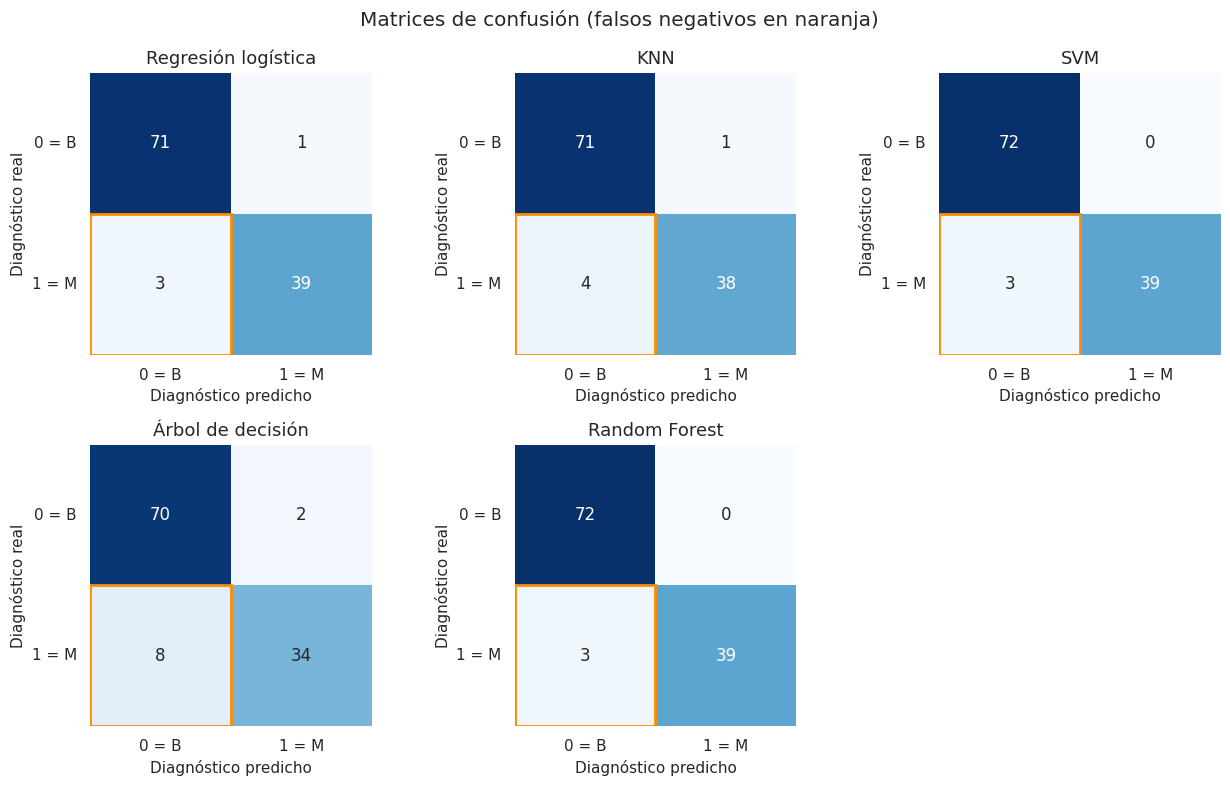

,Modelo,Falsos_negativos_M
0,Regresión logística,3
1,SVM,3
2,Random Forest,3
3,KNN,4
4,Árbol de decisión,8


Cada falso negativo es un caso maligno (1 = M) clasificado como benigno (0 = B). Un conteo mayor indica que el modelo dejó sin detectar más casos malignos en este test.


In [19]:
from matplotlib.patches import Rectangle

matrices_confusion = {
    nombre_modelo: confusion_matrix(y_test, y_pred_por_modelo[nombre_modelo], labels=[0, 1])
    for nombre_modelo in NOMBRES_MODELOS
}
maximo_matriz = max(matriz.max() for matriz in matrices_confusion.values())

fig_confusion, ejes_confusion = plt.subplots(2, 3, figsize=(13, 8))
etiquetas_diagnostico = ["0 = B", "1 = M"]
filas_falsos_negativos = []

for eje, (nombre_modelo, matriz) in zip(ejes_confusion.flat, matrices_confusion.items()):
    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        vmin=0,
        vmax=maximo_matriz,
        cbar=False,
        square=True,
        xticklabels=etiquetas_diagnostico,
        yticklabels=etiquetas_diagnostico,
        ax=eje,
    )
    eje.set(title=nombre_modelo, xlabel="Diagnóstico predicho", ylabel="Diagnóstico real")
    eje.tick_params(axis="y", labelrotation=0)
    # La fila 1 y la columna 0 contienen los falsos negativos de malignidad.
    eje.add_patch(Rectangle((0, 1), 1, 1, fill=False, edgecolor="darkorange", linewidth=2))
    filas_falsos_negativos.append({
        "Modelo": nombre_modelo,
        "Falsos_negativos_M": int(matriz[1, 0]),
    })

ejes_confusion.flat[-1].set_visible(False)
fig_confusion.suptitle("Matrices de confusión (falsos negativos en naranja)")
fig_confusion.tight_layout()
plt.show()

resumen_falsos_negativos = (
    pd.DataFrame(filas_falsos_negativos)
    .sort_values("Falsos_negativos_M", kind="stable")
    .reset_index(drop=True)
)
display(resumen_falsos_negativos)
print(
    "Cada falso negativo es un caso maligno (1 = M) clasificado como benigno (0 = B). "
    "Un conteo mayor indica que el modelo dejó sin detectar más casos malignos en este test."
)

### 5.4. Curvas ROC comparadas

Las cinco curvas quedan por encima de la diagonal, pero separadas en su capacidad de ordenar casos a través de umbrales. Random Forest presenta el AUC más alto (0,9980), seguido de regresión logística (0,9960), SVM (0,9947), KNN (0,9825) y árbol (0,8770). Las curvas de los tres primeros se concentran cerca de la esquina superior izquierda y sus AUC son muy próximos; el árbol muestra una trayectoria claramente inferior y KNN queda en posición intermedia. El AUC resume discriminación por umbrales, no calibración ni el error al umbral fijado: por eso el mismo Recall_M de los tres mejores coexiste con AUC distintos. Estos valores son estimaciones empíricas de una única partición.

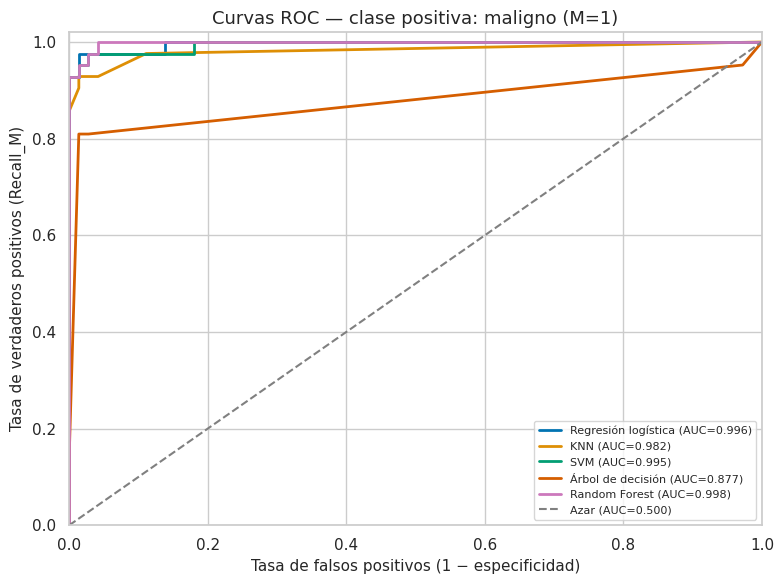

In [20]:
# 5.4 — cinco curvas ROC desde los scores comunes de 5.1.
_requeridas_roc = ("y_score_por_modelo", "y_test", "NOMBRES_MODELOS")
_faltantes_roc = [nombre for nombre in _requeridas_roc if nombre not in globals()]
if _faltantes_roc:
    raise RuntimeError("No están disponibles las dependencias de la sección 5.1: " + ", ".join(_faltantes_roc))
_y_roc = np.asarray(y_test)
if _y_roc.ndim != 1 or set(np.unique(_y_roc)) != {0, 1}:
    raise ValueError("y_test debe ser un vector con ambas clases, 1=M y 0=B.")
_faltan_scores_roc = set(NOMBRES_MODELOS) - set(y_score_por_modelo)
if _faltan_scores_roc:
    raise ValueError(f"Faltan puntuaciones para las cinco curvas: {sorted(_faltan_scores_roc)}")

curvas_roc = {}
_filas_auc = []
fig, ax = plt.subplots(figsize=(8, 6))
for nombre, color in zip(NOMBRES_MODELOS, sns.color_palette("colorblind", len(NOMBRES_MODELOS))):
    # Son probabilidades de M o decision_function orientada a M por 5.1.
    # No se usa y_pred binario ni se vuelve a ajustar ningún estimador.
    score = y_score_por_modelo[nombre]
    if isinstance(score, pd.Series) and not score.index.equals(y_test.index):
        raise ValueError(f"{nombre}: índices de los scores desalineados con y_test.")
    score = np.asarray(score, dtype=float)
    if score.ndim != 1 or len(score) != len(_y_roc) or not np.isfinite(score).all():
        raise ValueError(f"{nombre}: se requiere un score finito por muestra de test.")
    fpr, tpr, umbrales = roc_curve(_y_roc, score, pos_label=1)
    auc_observado = float(roc_auc_score(_y_roc, score))
    curvas_roc[nombre] = {"fpr": fpr, "tpr": tpr, "umbrales": umbrales, "auc": auc_observado}
    _filas_auc.append({"Modelo": nombre, "ROC_AUC": auc_observado})
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{nombre} (AUC={auc_observado:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC=0.500)")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Tasa de falsos positivos (1 − especificidad)",
       ylabel="Tasa de verdaderos positivos (Recall_M)", title="Curvas ROC — clase positiva: maligno (M=1)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
auc_roc = pd.DataFrame(_filas_auc)


### 5.5. Análisis de errores y elección del modelo

En el test, SVM y Random Forest comparten los mejores valores de Precision_M, Recall_M y F1_M; la regresión logística comparte su Recall y presenta tres falsos negativos. KNN omitió cuatro malignos y el árbol ocho. La decisión de preferir el bosque se explica por su AUC algo mayor entre los modelos empatados en falsos negativos, no por una ventaja demostrada estadísticamente. Accuracy aporta contexto —los cinco superan 0,91 y la referencia mayoritaria es 0,6316—, pero no reemplaza la revisión específica de omisiones malignas. La selección se hace con el mismo test usado para medir, de modo que su rendimiento reportado puede ser optimista.

In [21]:
# Comparación académica basada en los resultados observados.
requeridas_55 = ("resultados_df", "y_pred_por_modelo", "y_test")
faltantes_55 = [nombre for nombre in requeridas_55 if nombre not in globals()]
if faltantes_55:
    print("No se calcula el análisis de errores porque faltan estas dependencias: " + ", ".join(faltantes_55))
else:
    columnas_55 = {"Modelo", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"}
    if not columnas_55.issubset(resultados_df.columns):
        raise ValueError("resultados_df no contiene todas las métricas requeridas para 5.5.")
    if set(resultados_df["Modelo"].tolist()) != set(NOMBRES_MODELOS):
        raise ValueError("resultados_df debe incluir exactamente los cinco clasificadores acordados.")
    faltan_preds_55 = [n for n in NOMBRES_MODELOS if n not in y_pred_por_modelo]
    if faltan_preds_55:
        raise ValueError("Faltan predicciones de: " + ", ".join(faltan_preds_55))
    y_real = np.asarray(y_test).ravel()
    if not set(np.unique(y_real).tolist()).issubset({0, 1}) or set(np.unique(y_real)) != {0, 1}:
        raise ValueError("y_test debe codificar ambas clases: 0=B y 1=M.")
    conteo_fn = {}
    for nombre in NOMBRES_MODELOS:
        pred = np.asarray(y_pred_por_modelo[nombre]).ravel()
        if len(pred) != len(y_real):
            raise ValueError(f"{nombre}: predicciones y y_test tienen dimensiones distintas.")
        if not set(np.unique(pred).tolist()).issubset({0, 1}):
            raise ValueError(f"{nombre}: predicciones fuera de la codificación 0=B, 1=M.")
        conteo_fn[nombre] = int(np.sum((y_real == 1) & (pred == 0)))
    analisis_df = resultados_df.copy()
    analisis_df["Falsos_negativos_M"] = analisis_df["Modelo"].map(conteo_fn)
    if analisis_df["Falsos_negativos_M"].isna().any():
        raise ValueError("No fue posible asociar todos los conteos de falsos negativos a los modelos.")
    print("Conteos de falsos negativos de malignidad en el conjunto de prueba:")
    display(analisis_df[["Modelo", "Falsos_negativos_M"]].sort_values(
        "Falsos_negativos_M", kind="stable"
    ).reset_index(drop=True))
    # Regla declarada: minimizar FN; desempates por Recall_M, F1_M y ROC_AUC.
    analisis_df = analisis_df.sort_values(
        ["Falsos_negativos_M", "Recall_M", "F1_M", "ROC_AUC"],
        ascending=[True, False, False, False], kind="stable"
    ).reset_index(drop=True)
    recomendado = analisis_df.iloc[0]


Conteos de falsos negativos de malignidad en el conjunto de prueba:


,Modelo,Falsos_negativos_M
0,Regresión logística,3
1,SVM,3
2,Random Forest,3
3,KNN,4
4,Árbol de decisión,8


## 6. Interpretación y discusión

### 6.1. Importancia de características en Random Forest

En el bosque entrenado, `area_worst` ocupa el primer lugar (importancia aproximada 0,15), seguida de `concave points_worst` (≈ 0,13) y `radius_worst` (≈ 0,10); después aparecen `concave points_mean`, `perimeter_worst` y `perimeter_mean` (cada una alrededor de 0,08). El predominio de área, radio y puntos cóncavos es coherente con las diferencias descriptivas de tamaño y concavidad entre diagnósticos. Sin embargo, las variables de tamaño están fuertemente correlacionadas, por lo que el orden puede reflejar información compartida y depende del bosque ajustado. La importancia por reducción de impureza describe uso predictivo interno; no mide efecto causal ni confirma relevancia clínica.

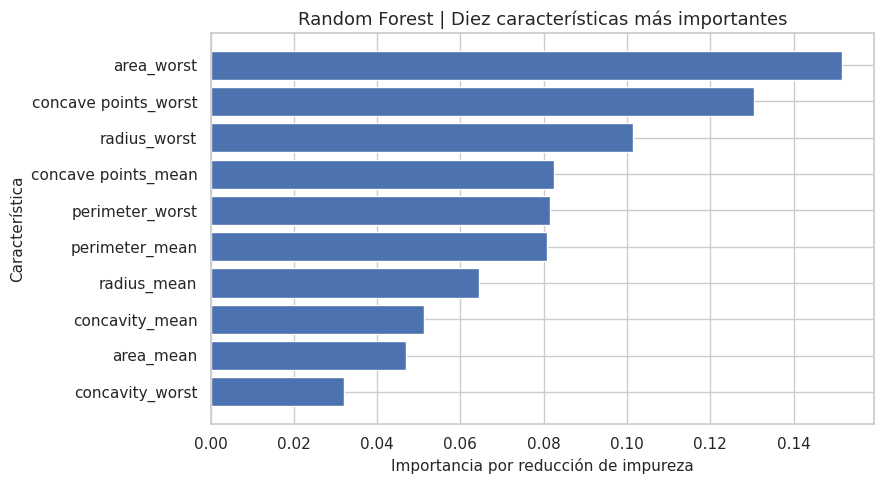

Las importancias resumen cuánto contribuyó cada característica a reducir la impureza en el bosque entrenado. Las conclusiones causales o clínicas requieren evidencia independiente.


In [22]:
bosque_entrenado = modelos_entrenados["Random Forest"]
importancias_bosque = bosque_entrenado.feature_importances_

if (
    not X.columns.equals(pd.Index(bosque_entrenado.feature_names_in_))
    or len(importancias_bosque) != len(X.columns)
):
    raise ValueError("Las importancias del bosque deben corresponder a las columnas de X, en el mismo orden.")

importancias_principales = (
    pd.Series(importancias_bosque, index=X.columns)
    .nlargest(10)
    .sort_values(ascending=True, kind="stable")
)
fig_importancias, eje_importancias = plt.subplots(figsize=(9, 5))
eje_importancias.barh(importancias_principales.index, importancias_principales.values)
eje_importancias.set(
    title="Random Forest | Diez características más importantes",
    xlabel="Importancia por reducción de impureza",
    ylabel="Característica",
)
fig_importancias.tight_layout()
plt.show()

print(
    "Las importancias resumen cuánto contribuyó cada característica a reducir la impureza "
    "en el bosque entrenado. Las conclusiones causales o clínicas requieren evidencia independiente."
)

### 6.2. Síntesis del EDA frente a los resultados

El EDA encontró una prevalencia maligna de 37,26 %, medianas malignas superiores en tamaño, textura y concavidad, y correlaciones casi perfectas entre varias medidas de tamaño. El patrón es coherente con que el bosque otorgue mayor importancia a `area_worst` y `radius_worst`, y con el buen desempeño de los clasificadores en la partición; no permite afirmar que una variable cause malignidad ni que por sí sola explique el rendimiento. Los histogramas muestran solapamiento entre las distribuciones de variables individuales; por separado, las matrices de confusión registran tres falsos negativos para cada uno de los tres modelos líderes. Esos casos no se estudiaron individualmente, por lo que no se determinaron las causas de su clasificación errónea.

La evaluación final contiene 114 casos y procede de una sola partición estratificada. KNN seleccionó k mediante CV de cinco pliegues en entrenamiento; SVM evaluó una configuración fija con CV interna. No se realizó una comparación homogénea por validación cruzada de los cinco modelos ni validación externa; por ello, los resultados describen este experimento y su incertidumbre de generalización no queda cuantificada.

### 6.3. Conclusiones y recomendaciones

## Conclusiones

En esta partición, Random Forest encabeza la regla académica de minimizar falsos negativos y desempatar por Recall_M, F1_M y ROC-AUC: tuvo 3 falsos negativos de 42 malignos, Recall_M = 0,9286, F1_M = 0,9630, Accuracy = 0,9737 y AUC = 0,9980. SVM comparte los tres primeros indicadores y alcanza el mismo Accuracy, con AUC = 0,9947; la ventaja observada del bosque en AUC es pequeña y descriptiva. La regresión logística también tuvo 3 falsos negativos; KNN tuvo 4 y el árbol 8.

El resultado sustenta que los cinco clasificadores separaron mejor las clases que la referencia de predecir siempre benigno en este test; el bosque fue el primero bajo el criterio adoptado. No demuestra que sea superior en la población ni que su rendimiento se replique: el ganador se eligió usando la propia partición de prueba, hay solo 42 malignos evaluados y no se realizó validación externa. La redundancia entre predictores limita además la interpretación individual de coeficientes e importancias. Para sostener una afirmación de generalización haría falta una comparación homogénea con validación cruzada anidada o una nueva muestra independiente; las cifras actuales deben entenderse como desempeño observado del laboratorio, no como evidencia clínica.

In [23]:
import pandas as pd

nombres_esperados = list(NOMBRES_MODELOS)
metricas_esperadas = ["Modelo", "Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"]
conclusiones_generadas = False
conclusion_modelo_recomendado = None
conclusion_metricas_resumen = None

if "resultados_df" not in globals() or "analisis_df" not in globals():
    print("No se genera la recomendación porque faltan los resultados de evaluación o el análisis de errores.")
else:
    if not set(metricas_esperadas).issubset(resultados_df.columns):
        raise ValueError("resultados_df no tiene el esquema requerido para la recomendación.")
    if set(resultados_df["Modelo"]) != set(nombres_esperados):
        raise ValueError("resultados_df debe contener exactamente una fila por cada modelo.")
    if "Falsos_negativos_M" not in analisis_df.columns or set(analisis_df["Modelo"]) != set(nombres_esperados):
        raise ValueError("El análisis debe contener los falsos negativos de los cinco modelos.")
    if analisis_df["Modelo"].duplicated().any() or resultados_df["Modelo"].duplicated().any():
        raise ValueError("Se esperaba una sola fila por clasificador.")
    fila = analisis_df.sort_values(
        ["Falsos_negativos_M", "Recall_M", "F1_M", "ROC_AUC"],
        ascending=[True, False, False, False], kind="stable"
    ).iloc[0]
    conclusion_modelo_recomendado = fila["Modelo"]
    conclusion_metricas_resumen = fila[
        ["Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC", "Falsos_negativos_M"]
    ].to_dict()
    conclusiones_generadas = True
    resumen_conclusion = pd.DataFrame([{
        "Modelo según criterio académico": conclusion_modelo_recomendado,
        "Accuracy": fila["Accuracy"],
        "Precision_M": fila["Precision_M"],
        "Recall_M": fila["Recall_M"],
        "F1_M": fila["F1_M"],
        "ROC_AUC": fila["ROC_AUC"],
        "Falsos_negativos_M": int(fila["Falsos_negativos_M"]),
    }])
    display(resumen_conclusion.round(4))

,Modelo según criterio académico,Accuracy,Precision_M,Recall_M,F1_M,ROC_AUC,Falsos_negativos_M
0,Random Forest,0.9737,1.0,0.9286,0.963,0.998,3


## 7. Control de calidad del análisis

### 7.1. Resultados de los controles y alcance de la certificación

### Comprobaciones automáticas

La tabla de controles informa las condiciones contrastadas con las variables y resultados disponibles: presencia de objetos, dimensiones, codificación de clases, registro de modelos y coherencia de predicciones y conteos de falsos negativos. `PASS` indica que la condición automática se observó; `FAIL` identifica una inconsistencia; `PENDIENTE` señala que no hay evidencia suficiente para esa condición.

### Alcance de las verificaciones que requieren evidencia adicional

Dos aspectos no pueden certificarse únicamente con los indicadores automáticos: que el escalador se ajustó exclusivamente con observaciones de entrenamiento en todo el flujo y que el notebook completó una ejecución integral en una sesión limpia de Google Colab. Permanecen identificados como `PENDIENTE` por el alcance de la evidencia disponible; no representan fallos observados de los cálculos ni resultados afirmativos de validación. La inspección automatizada tampoco demuestra ausencia absoluta de fuga de información ni generalización externa.

In [24]:
# Los controles automáticos conservan sus estados según la evidencia disponible.
from IPython.display import HTML, display

filas_verificacion = []
def _reportar_estado(etiqueta, estado, detalle=""):
    if estado not in ("PASS", "FAIL", "PENDIENTE"):
        raise ValueError("Estado de verificación desconocido.")
    filas_verificacion.append({
        "Estado": estado,
        "Comprobación": etiqueta,
        "Detalle verificable": str(detalle),
    })

compartidas = ["df_raw", "df_clean", "X", "y", "X_train", "X_test", "y_train", "y_test",
               "escalador", "X_train_scaled", "X_test_scaled"]
for nombre in compartidas:
    _reportar_estado(f"variable compartida {nombre}", "PASS" if nombre in globals() else "PENDIENTE",
                     "presente" if nombre in globals() else "no está definida en la sesión")

if "sys" in globals():
    _reportar_estado("intérprete Python 3", "PASS" if sys.version_info.major == 3 else "FAIL",
                     sys.version.split()[0])
else:
    _reportar_estado("intérprete Python 3", "PENDIENTE", "no se pudo consultar sys.version_info")

if "RANDOM_STATE" in globals():
    _reportar_estado("RANDOM_STATE configurado en 42", "PASS" if RANDOM_STATE == 42 else "FAIL", str(RANDOM_STATE))
else:
    _reportar_estado("RANDOM_STATE configurado en 42", "PENDIENTE", "RANDOM_STATE no está disponible en el entorno")

if "modelos_entrenados" not in globals() or "tipo_entrada" not in globals():
    _reportar_estado("registro y tipos de los cinco modelos", "PENDIENTE", "los diccionarios de modelos no están disponibles")
else:
    faltantes_modelos = [n for n in NOMBRES_MODELOS if n not in modelos_entrenados]
    faltantes_tipos = [n for n in NOMBRES_MODELOS if n not in tipo_entrada]
    extras_modelos = [n for n in modelos_entrenados if n not in NOMBRES_MODELOS]
    tipos_invalidos = {n: tipo_entrada[n] for n in tipo_entrada if n in NOMBRES_MODELOS and tipo_entrada[n] not in ("escalado", "original")}
    if extras_modelos or tipos_invalidos:
        _reportar_estado("registro y tipos de los cinco modelos", "FAIL", f"extras={extras_modelos}; tipos inválidos={tipos_invalidos}")
    elif faltantes_modelos or faltantes_tipos:
        _reportar_estado("registro y tipos de los cinco modelos", "PENDIENTE", f"faltan modelos={faltantes_modelos}; faltan tipos={faltantes_tipos}")
    else:
        _reportar_estado("registro y tipos de los cinco modelos", "PASS", "nombres exactos y valores de tipo válidos")

partes = ("X_train", "X_test", "y_train", "y_test", "X_train_scaled", "X_test_scaled")
if not all(nombre in globals() for nombre in partes):
    _reportar_estado("dimensiones train/test originales y escaladas", "PENDIENTE", "no están disponibles todas las particiones o matrices escaladas")
else:
    try:
        formas = {nombre: np.shape(globals()[nombre]) for nombre in partes}
        vectores = ("y_train", "y_test")
        matrices = ("X_train", "X_test", "X_train_scaled", "X_test_scaled")
        if any(len(formas[nombre]) != 1 for nombre in vectores):
            raise ValueError("y_train y y_test deben ser vectores unidimensionales")
        if any(len(formas[nombre]) != 2 for nombre in matrices):
            raise ValueError("las matrices X deben ser bidimensionales")
        dimensiones_ok = (
            formas["X_train"][0] == formas["y_train"][0]
            and formas["X_test"][0] == formas["y_test"][0]
            and formas["X_train"] == formas["X_train_scaled"]
            and formas["X_test"] == formas["X_test_scaled"]
            and formas["X_train"][1] == formas["X_test"][1]
        )
        _reportar_estado("dimensiones train/test originales y escaladas", "PASS" if dimensiones_ok else "FAIL",
                         f"formas={formas}")
    except Exception as error_forma:
        _reportar_estado("dimensiones train/test originales y escaladas", "FAIL",
                         f"dimensión inválida: {type(error_forma).__name__}: {error_forma}")

if "y" not in globals():
    _reportar_estado("codificación 1=M y 0=B", "PENDIENTE", "y no está disponible")
else:
    valores_y = set(np.asarray(y).ravel().tolist())
    if not valores_y.issubset({0, 1}):
        _reportar_estado("codificación 1=M y 0=B", "FAIL", f"valores observados={valores_y}")
    elif "df_clean" not in globals() or "diagnosis" not in getattr(df_clean, "columns", []):
        _reportar_estado("significado semántico de las etiquetas", "PENDIENTE", "no hay diagnosis de referencia para comprobar M→1/B→0")
    else:
        diagnosis = df_clean["diagnosis"].astype(str).str.upper().to_numpy()
        etiquetas = np.asarray(y).ravel()
        semantica_ok = (len(diagnosis) == len(etiquetas) and
                        np.array_equal(etiquetas, np.where(diagnosis == "M", 1, np.where(diagnosis == "B", 0, -1))))
        _reportar_estado("codificación 1=M y 0=B contrastada con diagnosis", "PASS" if semantica_ok else "FAIL")

# Indicador parcial: la cantidad de filas vista por el escalador debe coincidir
# con train, pero esto no demuestra por sí sola sobre qué datos se llamó fit().
if "escalador" not in globals() or "X_train" not in globals():
    _reportar_estado("indicador parcial: n_samples_seen_ frente a filas de train", "PENDIENTE", "el escalador o X_train no están disponibles")
else:
    try:
        observadas = getattr(escalador, "n_samples_seen_", None)
        if observadas is None:
            _reportar_estado("indicador parcial: n_samples_seen_ frente a filas de train", "PENDIENTE", "el escalador no expone n_samples_seen_")
        else:
            coincide_train = bool(np.all(np.asarray(observadas) == len(X_train)))
            _reportar_estado("indicador parcial: n_samples_seen_ coincide con filas de train",
                             "PASS" if coincide_train else "FAIL",
                             "esta coincidencia no prueba que fit() usara exclusivamente train")
    except Exception as error_escalador:
        _reportar_estado("indicador parcial: n_samples_seen_ frente a filas de train", "FAIL",
                         f"no se pudo comprobar: {type(error_escalador).__name__}: {error_escalador}")

# Indicador limitado a llamadas directas; no constituye una auditoría completa.
import re
historial_codigo = globals().get("In") or globals().get("_ih")
if historial_codigo is not None and len(historial_codigo) > 1:
    codigo_ejecutado = "\n".join(historial_codigo[1:-1])
    fit_directo_en_test = bool(re.search(r"\.fit(?:_transform)?\s*\(\s*X_test(?:_scaled)?\b", codigo_ejecutado))
    _reportar_estado("búsqueda parcial de llamadas directas fit(X_test)",
                     "FAIL" if fit_directo_en_test else "PASS",
                     "un resultado negativo no descarta otras formas de fuga")
else:
    _reportar_estado("búsqueda parcial de llamadas directas fit(X_test)", "PENDIENTE", "no hay historial de código disponible en la sesión")

# La revisión del flujo completo requiere evidencia metodológica adicional.
_reportar_estado("revisión metodológica de la posible fuga de información", "PENDIENTE",
                 "el indicador no permite certificar por sí solo el flujo completo de preprocesamiento y ajuste")

if not all(nombre in globals() for nombre in ("resultados_df", "y_pred_por_modelo", "y_score_por_modelo", "y_test")):
    _reportar_estado("métricas, predicciones y scores ROC", "PENDIENTE", "resultados y predicciones de los cinco modelos no están disponibles")
else:
    esquema_ok = list(resultados_df.columns) == metricas_esperadas if "metricas_esperadas" in globals() else list(resultados_df.columns) == ["Modelo", "Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"]
    contenido_ok = (set(resultados_df["Modelo"]) == set(NOMBRES_MODELOS)
                    and all(n in y_pred_por_modelo and n in y_score_por_modelo for n in NOMBRES_MODELOS)
                    and all(len(y_pred_por_modelo[n]) == len(y_test) and len(y_score_por_modelo[n]) == len(y_test) for n in NOMBRES_MODELOS))
    if not esquema_ok or not contenido_ok:
        _reportar_estado("resultados y predicciones del conjunto de prueba", "FAIL", "esquema, modelos o longitudes inconsistentes")
    else:
        _reportar_estado("resultados y predicciones del conjunto de prueba", "PASS", "cinco modelos con longitudes compatibles")

if ("analisis_df" not in globals() or "Falsos_negativos_M" not in getattr(analisis_df, "columns", [])
        or "y_test" not in globals() or "y_pred_por_modelo" not in globals()):
    _reportar_estado("selección y conclusiones coherentes con valores reales", "PENDIENTE", "faltan los resultados, predicciones o resúmenes asociados")
else:
    conteos_recalculados = {
        n: int(np.sum((np.asarray(y_test).ravel() == 1) & (np.asarray(y_pred_por_modelo[n]).ravel() == 0)))
        for n in NOMBRES_MODELOS if n in y_pred_por_modelo
    }
    conteos_registrados = analisis_df.set_index("Modelo")["Falsos_negativos_M"].to_dict()
    analisis_coherente = (set(conteos_recalculados) == set(NOMBRES_MODELOS)
                          and all(conteos_registrados.get(n) == conteos_recalculados[n] for n in conteos_recalculados))
    if not analisis_coherente:
        _reportar_estado("falsos negativos en 5.5 coinciden con y_test/predicciones", "FAIL")
    else:
        _reportar_estado("falsos negativos en 5.5 coinciden con y_test/predicciones", "PASS")
    seleccion_esperada = analisis_df.sort_values(
        ["Falsos_negativos_M", "Recall_M", "F1_M", "ROC_AUC"],
        ascending=[True, False, False, False], kind="stable"
    ).iloc[0]["Modelo"]
    if not globals().get("conclusiones_generadas", False):
        _reportar_estado("selección de 6.3 deriva de los valores reales", "PENDIENTE", "la recomendación y sus cifras no están disponibles")
    else:
        resumen_esperado = resultados_df.set_index("Modelo").loc[seleccion_esperada]
        resumen = globals().get("conclusion_metricas_resumen") or {}
        metricas_coherentes = (globals().get("conclusion_modelo_recomendado") == seleccion_esperada
                               and all(np.isclose(resumen.get(m, np.nan), resumen_esperado[m]) for m in
                                       ("Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"))
                               and int(resumen.get("Falsos_negativos_M", -1)) == conteos_recalculados[seleccion_esperada])
        _reportar_estado("selección y cifras de 6.3 coinciden con métricas/FN", "PASS" if metricas_coherentes else "FAIL")

# La ausencia de evidencia integral de ejecución en Colab se identifica por separado.
_reportar_estado("certificación de ejecución integral en Google Colab", "PENDIENTE", "Este control automático no certifica por sí solo una ejecución desde una sesión limpia de Colab")

verificacion_df = pd.DataFrame(
    filas_verificacion,
    columns=["Estado", "Comprobación", "Detalle verificable"],
)
resumen_estados_df = (
    verificacion_df["Estado"]
    .value_counts()
    .reindex(["PASS", "FAIL", "PENDIENTE"], fill_value=0)
    .rename_axis("Estado")
    .reset_index(name="Cantidad")
)
display(resumen_estados_df)

indicadores_revision = verificacion_df[verificacion_df["Comprobación"].isin([
    "revisión metodológica de la posible fuga de información",
    "certificación de ejecución integral en Google Colab",
])].copy()
comprobaciones_automaticas = verificacion_df.drop(index=indicadores_revision.index).copy()
tabla_controles_automaticos_html = comprobaciones_automaticas.to_html(index=False, escape=True)
display(HTML(
    "<details><summary>Ver controles automáticos</summary>"
    + tabla_controles_automaticos_html
    + "</details>"
))
tabla_alcance_certificacion_html = indicadores_revision.to_html(index=False, escape=True)
display(HTML(
    "<details><summary>Ver alcance de certificación</summary>"
    + tabla_alcance_certificacion_html
    + "</details>"
))

,Estado,Cantidad
0,PASS,21
1,FAIL,0
2,PENDIENTE,2


Estado,Comprobación,Detalle verificable
PASS,variable compartida df_raw,presente
PASS,variable compartida df_clean,presente
PASS,variable compartida X,presente
PASS,variable compartida y,presente
PASS,variable compartida X_train,presente
PASS,variable compartida X_test,presente
PASS,variable compartida y_train,presente
PASS,variable compartida y_test,presente
PASS,variable compartida escalador,presente
PASS,variable compartida X_train_scaled,presente


Estado,Comprobación,Detalle verificable
PENDIENTE,revisión metodológica de la posible fuga de información,el indicador no permite certificar por sí solo el flujo completo de preprocesamiento y ajuste
PENDIENTE,certificación de ejecución integral en Google Colab,Este control automático no certifica por sí solo una ejecución desde una sesión limpia de Colab
